# Đề tài 8 — PCA, SVD và xấp xỉ hạng thấp
## Notebook 1/3 — Phần A: Phát triển phương pháp và cài đặt

| Notebook | Nội dung |
|---|---|
| **01_PhanA_CaiDat** (notebook này) | A.1 PCA qua trị riêng và SVD, độ ổn định số · A.2 SVD ngẫu nhiên, PCA tăng dần · A.3 PCA hàm nhân, bộ tự mã hóa tuyến tính · A.4 $T^2$ Hotelling và SPE |
| 02_PhanB_ChungMinh | B.1–B.6: phát biểu, chứng minh, kiểm chứng số |
| 03_PhanC_BaiTap | C.1–C.4: tính tay, hiệp phương sai vs tương quan, Johnson–Lindenstrauss, so sánh thuật toán SVD |

**Tổ chức mã.** Các ô có nhãn `# [CORE]` trong notebook này là cài đặt gốc của Phần A, được xuất nguyên văn sang `src/pca_core.py`. Notebook 2, 3 và Phần D **import từ `pca_core.py`** (không chép lại mã). Ô cuối notebook kiểm tra `pca_core.py` cho kết quả trùng với các cài đặt ở đây. Nếu sửa một cài đặt, sửa ở cả hai nơi (hoặc sửa ở đây rồi chạy lại `build`).

**Quy ước tái lập** (theo yêu cầu đề):
- Mọi thuật toán cốt lõi **tự cài bằng NumPy**; `sklearn`, `scipy` chỉ dùng để **đối chiếu** và lấy phân vị phân phối.
- Hạt giống cố định (`SEED = 42`); kết quả có yếu tố ngẫu nhiên báo cáo dạng **trung bình ± độ lệch chuẩn trên 5 lần chạy**.

**Ký hiệu:** $X\in\mathbb{R}^{n\times d}$ (mỗi hàng một mẫu), $\mu$ là vector trung bình, $X_c=X-\mathbf{1}\mu^\top$, $\Sigma=\frac{1}{n-1}X_c^\top X_c$, $\lambda_1\ge\dots\ge\lambda_d$ là trị riêng của $\Sigma$, $\sigma_i$ là giá trị kỳ dị.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import subspace_angles
from sklearn.datasets import load_wine, make_circles
from sklearn.decomposition import PCA, IncrementalPCA, KernelPCA
from sklearn.utils.extmath import randomized_svd as sk_randomized_svd

SEED = 42
N_RUNS = 5                      # số lần chạy lặp để báo cáo trung bình ± độ lệch chuẩn
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

def mean_std(values, fmt=".3g"):
    # Chuỗi "trung bình ± độ lệch chuẩn" (độ lệch chuẩn mẫu, ddof=1)
    v = np.asarray(values, dtype=float)
    return f"{v.mean():{fmt}} ± {v.std(ddof=1):{fmt}}"

def max_principal_angle_deg(A, B):
    # Góc chính lớn nhất (độ) giữa span(A) và span(B); = 0 nghĩa là hai không gian con trùng nhau
    return np.degrees(subspace_angles(A, B).max())

---
# Phần A — Phát triển phương pháp và cài đặt

## A.1 PCA qua trị riêng và qua SVD; so sánh độ ổn định số

**Hai cách tính cùng một đại lượng.**
1. *Trị riêng:* lập $\Sigma=\frac{1}{n-1}X_c^\top X_c$ rồi phân rã $\Sigma=V\Lambda V^\top$. Hướng chính là cột của $V$, phương sai là $\lambda_i$.
2. *SVD:* phân rã trực tiếp $X_c=U S V^\top$. Vì $\Sigma = V\frac{S^2}{n-1}V^\top$ nên hướng chính vẫn là cột của $V$ và $\lambda_i=\sigma_i^2/(n-1)$; tọa độ chính $T=X_cV=US$.

**Vì sao khác nhau về số học?** Số điều kiện $\kappa(X_c^\top X_c)=\kappa(X_c)^2$. Với độ chính xác máy $\varepsilon\approx 2.2\times10^{-16}$, thuật toán trị riêng ổn định ngược cho sai số tuyệt đối cỡ $\varepsilon\lambda_1$ trên mỗi trị riêng, nên sai số tương đối của $\lambda_i$ cỡ $\varepsilon\,\lambda_1/\lambda_i=\varepsilon\,(\sigma_1/\sigma_i)^2$. SVD làm việc trên $X_c$ cho sai số tương đối của $\sigma_i$ cỡ $\varepsilon\,\sigma_1/\sigma_i$. Khi $\sigma_1/\sigma_d>10^{8}$, cách trị riêng **mất toàn bộ chữ số** của thành phần nhỏ nhất.

In [2]:
# [CORE]
def pca_eig(X, k):
    # PCA bằng phân rã trị riêng của ma trận hiệp phương sai
    n = X.shape[0]
    mu = X.mean(axis=0)
    Xc = X - mu
    C = Xc.T @ Xc / (n - 1)                  # ma trận hiệp phương sai d x d
    lam, V = np.linalg.eigh(C)               # eigh: ma trận đối xứng -> trị riêng thực, tăng dần
    order = np.argsort(lam)[::-1]            # đổi sang giảm dần
    lam, V = lam[order], V[:, order]
    return mu, V[:, :k], lam                 # trung bình, d x k hướng chính, mọi trị riêng


def pca_svd(X, k):
    # PCA bằng SVD của ma trận dữ liệu đã quy tâm (cách sklearn dùng)
    n = X.shape[0]
    mu = X.mean(axis=0)
    Xc = X - mu
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)   # Xc = U diag(S) Vt
    lam = S**2 / (n - 1)                     # lambda_i = sigma_i^2 / (n-1)
    return mu, Vt[:k].T, lam


def fix_sign(W):
    # Vector riêng chỉ xác định đến dấu: chuẩn hóa để phần tử có |giá trị| lớn nhất của mỗi cột là dương
    idx = np.argmax(np.abs(W), axis=0)
    return W * np.sign(W[idx, np.arange(W.shape[1])])

### A.1.1 Đối chiếu với `sklearn` trên dữ liệu thật (Wine, đã chuẩn hóa)

In [3]:
wine = load_wine()
Xw = (wine.data - wine.data.mean(0)) / wine.data.std(0, ddof=1)   # chuẩn hóa (dùng ở A.1, A.3, C.2)
k = 5
mu_e, W_e, lam_e = pca_eig(Xw, k)
mu_s, W_s, lam_s = pca_svd(Xw, k)
sk = PCA(n_components=k, svd_solver="full").fit(Xw)

print("Phương sai (trị riêng) :", lam_e[:k])
print("Phương sai (SVD)       :", lam_s[:k])
print("Phương sai (sklearn)   :", sk.explained_variance_)
print("max |eig - sklearn|    :", np.abs(lam_e[:k] - sk.explained_variance_).max())
print("max |svd - sklearn|    :", np.abs(lam_s[:k] - sk.explained_variance_).max())
print("max |W_eig - W_sklearn| (sau chuẩn hóa dấu):", np.abs(fix_sign(W_e) - fix_sign(sk.components_.T)).max())
print("max |W_svd - W_sklearn| (sau chuẩn hóa dấu):", np.abs(fix_sign(W_s) - fix_sign(sk.components_.T)).max())

Phương sai (trị riêng) : [4.7059 2.497  1.4461 0.919  0.8532]
Phương sai (SVD)       : [4.7059 2.497  1.4461 0.919  0.8532]
Phương sai (sklearn)   : [4.7059 2.497  1.4461 0.919  0.8532]
max |eig - sklearn|    : 9.769962616701378e-15
max |svd - sklearn|    : 1.0658141036401503e-14
max |W_eig - W_sklearn| (sau chuẩn hóa dấu): 2.192690473634684e-15
max |W_svd - W_sklearn| (sau chuẩn hóa dấu): 6.772360450213455e-15


Với dữ liệu điều kiện tốt (Wine chuẩn hóa: $\kappa(X_c)\approx 6$), hai cách và `sklearn` trùng nhau đến sai số máy. Khác biệt chỉ lộ ra khi dữ liệu **điều kiện xấu**.

### A.1.2 Thí nghiệm độ ổn định số
Tạo $X_c = U\,\mathrm{diag}(s)\,V^\top$ với $U$, $V$ trực chuẩn ngẫu nhiên ($U$ trực giao với vector $\mathbf 1$ nên $X_c$ có trung bình 0 chính xác) và $s$ giảm đều theo thang log từ $1$ đến $1/\kappa$. Như vậy **biết trước đáp án đúng** $\lambda_i = s_i^2/(n-1)$. Đo sai số tương đối của trị riêng nhỏ nhất và góc giữa hướng chính cuối cùng tìm được với hướng đúng; lặp 5 hạt giống.

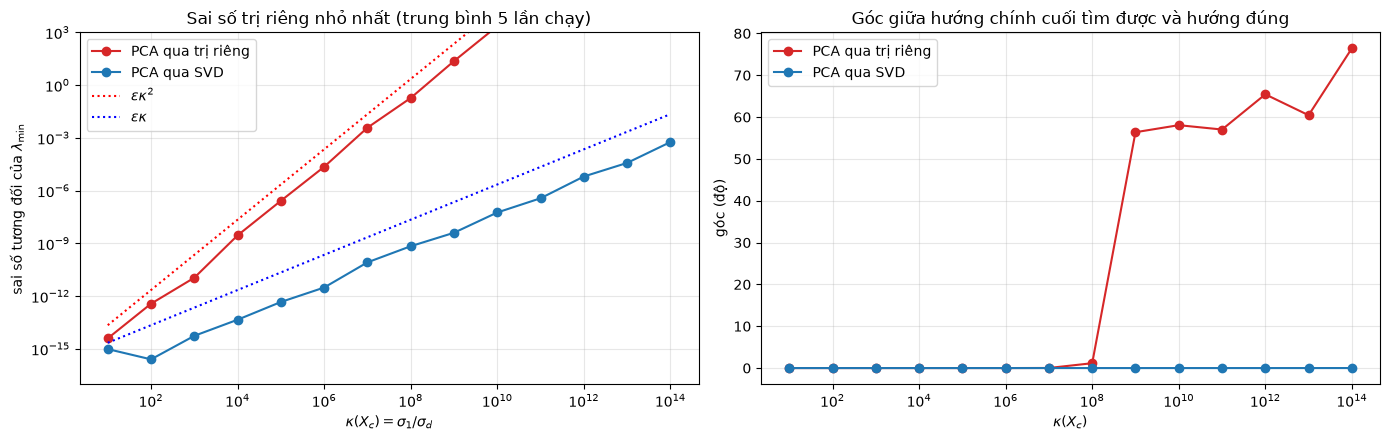

kappa = 1e 4: sai số lambda_min  eig = 2.84e-09 ± 2.03e-09 | svd = 4.55e-14 ± 3.79e-14
kappa = 1e 8: sai số lambda_min  eig = 0.185 ± 0.0978 | svd = 6.88e-10 ± 6.7e-10
kappa = 1e10: sai số lambda_min  eig = 2.24e+03 ± 1.39e+03 | svd = 5.7e-08 ± 5.26e-08
kappa = 1e12: sai số lambda_min  eig = 4.74e+07 ± 1.7e+07 | svd = 6.33e-06 ± 4.53e-06


In [4]:
def make_conditioned(n, d, kappa, rng):
    # Dữ liệu đã quy tâm có giá trị kỳ dị biết trước: s_1 = 1, s_d = 1/kappa
    G = rng.standard_normal((n, d))
    G -= G.mean(axis=0)                               # cột trực giao với vector 1
    U, _ = np.linalg.qr(G)
    V, _ = np.linalg.qr(rng.standard_normal((d, d)))
    s = np.logspace(0, -np.log10(kappa), d)
    return (U * s) @ V.T, s, V

n, d = 400, 20
kappas = np.logspace(1, 14, 14)          # bắt đầu từ 10: với kappa = 1 mọi sigma bằng nhau, hướng chính không xác định
res = {"eig": [], "svd": []}           # sai số tương đối của lambda_min, mỗi phần tử: list theo kappa
ang = {"eig": [], "svd": []}           # góc (độ) của hướng chính cuối
for seed in range(N_RUNS):
    rng = np.random.default_rng(SEED + seed)
    r_e, r_s, a_e, a_s = [], [], [], []
    for kap in kappas:
        Xc, s, V = make_conditioned(n, d, kap, rng)
        lam_true = s[-1]**2 / (n - 1)
        _, We, le = pca_eig(Xc, d)
        _, Ws, ls = pca_svd(Xc, d)
        r_e.append(abs(le[-1] - lam_true) / lam_true)
        r_s.append(abs(ls[-1] - lam_true) / lam_true)
        a_e.append(max_principal_angle_deg(We[:, -1:], V[:, -1:]))
        a_s.append(max_principal_angle_deg(Ws[:, -1:], V[:, -1:]))
    res["eig"].append(r_e); res["svd"].append(r_s); ang["eig"].append(a_e); ang["svd"].append(a_s)

eps = np.finfo(float).eps
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, c in [("eig", "tab:red"), ("svd", "tab:blue")]:
    m = np.array(res[name]); a = np.array(ang[name])
    ax[0].loglog(kappas, np.maximum(m.mean(0), 1e-17), "o-", c=c, label=f"PCA qua {'trị riêng' if name=='eig' else 'SVD'}")
    ax[1].semilogx(kappas, a.mean(0), "o-", c=c, label=f"PCA qua {'trị riêng' if name=='eig' else 'SVD'}")
ax[0].loglog(kappas, eps * kappas**2, "r:", label=r"$\varepsilon\kappa^2$")
ax[0].loglog(kappas, eps * kappas, "b:", label=r"$\varepsilon\kappa$")
ax[0].set(xlabel=r"$\kappa(X_c)=\sigma_1/\sigma_d$", ylabel=r"sai số tương đối của $\lambda_{\min}$", ylim=(1e-17, 1e3),
          title="Sai số trị riêng nhỏ nhất (trung bình 5 lần chạy)")
ax[1].set(xlabel=r"$\kappa(X_c)$", ylabel="góc (độ)", title="Góc giữa hướng chính cuối tìm được và hướng đúng")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

for e in [4, 8, 10, 12]:
    i = e - 1                                  # vị trí của kappa = 10^e trong mảng kappas
    print(f"kappa = 1e{e:>2}: sai số lambda_min  eig = {mean_std(np.array(res['eig'])[:, i])}"
          f" | svd = {mean_std(np.array(res['svd'])[:, i])}")

**Kết luận A.1.** Sai số của cách trị riêng tăng theo $\varepsilon\kappa^2$, của SVD theo $\varepsilon\kappa$ — đúng như phân tích. Ở $\kappa=10^{8}$ cách trị riêng đã sai khoảng 20% ở $\lambda_{\min}$; từ $\kappa\approx10^{9}$ trở đi nó sai hoàn toàn (sai số tương đối $\gg 1$) và hướng chính cuối lệch hàng chục độ, trong khi SVD vẫn chính xác. Do đó mọi cài đặt về sau đều dùng SVD; cách trị riêng chỉ dùng khi $d$ nhỏ và dữ liệu điều kiện tốt (nó nhanh hơn khi $n\gg d$ vì chỉ phân rã ma trận $d\times d$).

---
## A.2 SVD ngẫu nhiên và PCA tăng dần

### A.2.1 SVD ngẫu nhiên (Halko, Martinsson & Tropp, 2011)
Muốn $k$ thành phần đầu của $A\in\mathbb{R}^{m\times n}$ mà không tính SVD đầy đủ ($O(mn\min(m,n))$):

1. **Phác thảo:** $\Omega\in\mathbb{R}^{n\times(k+p)}$ Gauss, $Y=A\Omega$. Các cột của $Y$ là tổ hợp ngẫu nhiên các cột của $A$ nên tập trung vào không gian cột chính. $p\approx 5$–$10$ là số cột "dự phòng" (oversampling).
2. **Lặp lũy thừa** $q$ lần: $Y\leftarrow (AA^\top)^qA\Omega$, làm giá trị kỳ dị thành $\sigma_i^{2q+1}$ → khoảng cách giữa $\sigma_k$ và $\sigma_{k+1}$ được khuếch đại, cần thiết khi phổ suy giảm chậm. Phải **trực chuẩn hóa lại (QR) sau mỗi lần nhân** để tránh mọi cột hội tụ về cùng một hướng do sai số làm tròn.
3. $Q=\mathrm{orth}(Y)$, $B=Q^\top A$ (nhỏ, $(k+p)\times n$), SVD $B=\tilde U S V^\top$, trả về $U=Q\tilde U$.

Chi phí $O(mn(k+p)(2q+1))$. Halko và cộng sự chứng minh $\mathbb{E}\|A-QQ^\top A\|_2 \le \big[(1+\sqrt{\tfrac{k}{p-1}})\sigma_{k+1}^{2q+1} + \tfrac{e\sqrt{k+p}}{p}\big(\sum_{j>k}\sigma_j^{2(2q+1)}\big)^{1/2}\big]^{1/(2q+1)}$, tức sai số tiến về mức tối ưu $\sigma_{k+1}$ khi $q$ tăng.

In [5]:
# [CORE]
def randomized_svd(A, k, p=10, q=2, rng=None):
    # SVD ngẫu nhiên (Halko-Martinsson-Tropp 2011, Thuật toán 4.4 + 5.1)
    rng = np.random.default_rng(rng)
    m, n = A.shape
    Omega = rng.standard_normal((n, k + p))      # (1) ma trận thử Gauss
    Q, _ = np.linalg.qr(A @ Omega)               #     Y = A Omega, trực chuẩn hóa
    for _ in range(q):                           # (2) lặp lũy thừa có trực chuẩn hóa lại
        Z, _ = np.linalg.qr(A.T @ Q)
        Q, _ = np.linalg.qr(A @ Z)
    B = Q.T @ A                                  # (3) ma trận nhỏ (k+p) x n
    Ub, S, Vt = np.linalg.svd(B, full_matrices=False)
    return (Q @ Ub)[:, :k], S[:k], Vt[:k]


def make_spectrum_matrix(m, n, s, rng):
    # Ma trận m x n có giá trị kỳ dị cho trước s (dài min(m, n))
    U, _ = np.linalg.qr(rng.standard_normal((m, len(s))))
    V, _ = np.linalg.qr(rng.standard_normal((n, len(s))))
    return (U * s) @ V.T

In [6]:
m, n, k = 2000, 500, 20
s_slow = 1.0 / np.sqrt(np.arange(1, n + 1))          # phổ suy giảm chậm: sigma_i = i^(-1/2)
qs = [0, 1, 2, 3, 4]
err = {q: [] for q in qs}; err_sk = []
for r in range(N_RUNS):
    rng = np.random.default_rng(SEED + r)
    A = make_spectrum_matrix(m, n, s_slow, rng)
    for q in qs:
        U, S, Vt = randomized_svd(A, k, p=10, q=q, rng=SEED + r)
        err[q].append(np.linalg.norm(A - (U * S) @ Vt, 2) / s_slow[k])     # tỉ số với mức tối ưu sigma_{k+1}
    U, S, Vt = sk_randomized_svd(A, k, n_oversamples=10, n_iter=2, random_state=SEED + r)
    err_sk.append(np.linalg.norm(A - (U * S) @ Vt, 2) / s_slow[k])

print("||A - A_k^rand||_2 / sigma_{k+1}   (1 = tối ưu theo Eckart-Young), phổ sigma_i = i^(-1/2)")
for q in qs:
    print(f"  tự cài, q = {q}: {mean_std(err[q], '.4f')}")
print(f"  sklearn randomized_svd (n_iter = 2): {mean_std(err_sk, '.4f')}")

||A - A_k^rand||_2 / sigma_{k+1}   (1 = tối ưu theo Eckart-Young), phổ sigma_i = i^(-1/2)
  tự cài, q = 0: 2.0480 ± 0.1363
  tự cài, q = 1: 1.1026 ± 0.0551
  tự cài, q = 2: 1.0145 ± 0.0141
  tự cài, q = 3: 1.0018 ± 0.0017
  tự cài, q = 4: 1.0003 ± 0.0004
  sklearn randomized_svd (n_iter = 2): 1.0153 ± 0.0066


Với phổ suy giảm chậm, không lặp lũy thừa ($q=0$) cho sai số lớn hơn mức tối ưu khoảng 2 lần; chỉ $q=2$ đã gần tối ưu, khớp với `sklearn` (cùng thuật toán). So sánh thời gian trên ma trận $10^4\times10^3$ được làm ở **C.4**.

### A.2.2 PCA tăng dần cho dữ liệu dòng
Dữ liệu đến theo từng lô $X^{(1)},X^{(2)},\dots$; không lưu toàn bộ. Ta chỉ giữ: số mẫu $n$, trung bình $\mu$, và phác thảo hạng $k$ của ma trận tán xạ dưới dạng $S_k V_k^\top$ ($k\times d$).

**Cập nhật** (Ross và cộng sự 2008 — cách `sklearn.IncrementalPCA` dùng). Với lô mới $X_b$ ($n_b$ mẫu, trung bình $\mu_b$), ma trận tán xạ của toàn bộ dữ liệu thỏa
$$\mathcal S_{\text{mới}}=\mathcal S_{\text{cũ}}+X_{b,c}^\top X_{b,c}+\frac{n\,n_b}{n+n_b}(\mu-\mu_b)(\mu-\mu_b)^\top .$$
Vì vậy chỉ cần SVD của ma trận xếp chồng
$$M=\begin{bmatrix} S_kV_k^\top\\ X_b-\mathbf 1\mu_b^\top\\ \sqrt{\tfrac{n n_b}{n+n_b}}(\mu-\mu_b)^\top\end{bmatrix}\quad\Rightarrow\quad M^\top M=\mathcal S_{\text{mới}}\ \ (\text{khi không cắt cụt}).$$
Giữ $k$ thành phần đầu của SVD($M$) làm phác thảo mới. Nếu $k=d$ kết quả **chính xác** bằng PCA toàn bộ; nếu $k<d$ là xấp xỉ (bỏ mất phần tán xạ ngoài không gian con).

In [7]:
# [CORE]
class StreamingPCA:
    # PCA tăng dần: chỉ lưu n, mu và phác thảo hạng k (S_k, V_k^T)
    def __init__(self, k):
        self.k, self.n, self.mean_ = k, 0, None

    def partial_fit(self, Xb):
        nb, mb = Xb.shape[0], Xb.mean(axis=0)
        if self.n == 0:
            M = Xb - mb
            new_mean = mb
        else:
            corr = np.sqrt(self.n * nb / (self.n + nb)) * (self.mean_ - mb)   # hiệu chỉnh do trung bình dịch chuyển
            M = np.vstack([self.S_[:, None] * self.Vt_, Xb - mb, corr])
            new_mean = (self.n * self.mean_ + nb * mb) / (self.n + nb)
        _, S, Vt = np.linalg.svd(M, full_matrices=False)
        self.S_, self.Vt_ = S[:self.k], Vt[:self.k]
        self.n += nb
        self.mean_ = new_mean
        self.explained_variance_ = self.S_**2 / (self.n - 1)
        return self

    @property
    def components(self):          # d x k
        return self.Vt_.T

In [8]:
d, k_true, batch = 50, 5, 100
ang_trunc, ang_full, ang_sk, var_err = [], [], [], []
for r in range(N_RUNS):
    rng = np.random.default_rng(SEED + r)
    L = rng.standard_normal((d, k_true)) * np.array([5, 4, 3, 2, 1.5])     # 5 hướng chính rõ ràng
    X_stream = rng.standard_normal((5000, k_true)) @ L.T + 0.5 * rng.standard_normal((5000, d)) + 10
    sp_k, sp_full = StreamingPCA(k_true), StreamingPCA(d)
    skp = IncrementalPCA(n_components=k_true)
    for start in range(0, len(X_stream), batch):            # dữ liệu đến theo từng lô 100 mẫu
        Xb = X_stream[start:start + batch]
        sp_k.partial_fit(Xb); sp_full.partial_fit(Xb); skp.partial_fit(Xb)
    _, W_batch, lam_batch = pca_svd(X_stream, k_true)        # PCA trên toàn bộ dữ liệu (đáp án)
    ang_trunc.append(max_principal_angle_deg(sp_k.components, W_batch))
    ang_full.append(max_principal_angle_deg(sp_full.components[:, :k_true], W_batch))
    ang_sk.append(max_principal_angle_deg(skp.components_.T, W_batch))
    var_err.append(np.abs(sp_k.explained_variance_ - lam_batch[:k_true]).max() / lam_batch[0])

print("Góc chính lớn nhất so với PCA toàn bộ dữ liệu (độ):")
print(f"  StreamingPCA tự cài, k = 5   : {mean_std(ang_trunc)}")
print(f"  StreamingPCA tự cài, k = d   : {mean_std(ang_full)}   (không cắt cụt -> chính xác)")
print(f"  sklearn IncrementalPCA, k = 5: {mean_std(ang_sk)}")
print(f"Sai số phương sai tương đối (k = 5): {mean_std(var_err)}")
print(f"Bộ nhớ: lưu {k_true}x{d} = {k_true*d} số thay vì {X_stream.size} số")

Góc chính lớn nhất so với PCA toàn bộ dữ liệu (độ):
  StreamingPCA tự cài, k = 5   : 0.000638 ± 0.000217
  StreamingPCA tự cài, k = d   : 3.11e-12 ± 1.31e-12   (không cắt cụt -> chính xác)
  sklearn IncrementalPCA, k = 5: 0.000638 ± 0.000217
Sai số phương sai tương đối (k = 5): 1.64e-08 ± 3.14e-09
Bộ nhớ: lưu 5x50 = 250 số thay vì 250000 số


PCA tăng dần với $k=d$ khớp PCA toàn bộ đến sai số máy (xác nhận công thức cập nhật); với $k=5$ sai lệch chỉ cỡ $10^{-3}$ độ và trùng với `sklearn`. Ở Phần D, lớp này cho phép **cập nhật mô hình trạng thái bình thường theo thời gian thực** từ dòng tín hiệu rung.

---
## A.3 PCA hàm nhân và bộ tự mã hóa tuyến tính

### A.3.1 PCA hàm nhân (Schölkopf, Smola & Müller 1998)
Ánh xạ ngầm $x\mapsto\phi(x)$ vào không gian đặc trưng, làm PCA ở đó. Chỉ cần tích vô hướng $K_{ij}=k(x_i,x_j)=\langle\phi(x_i),\phi(x_j)\rangle$.

1. **Quy tâm trong không gian đặc trưng:** $\tilde K = K - \mathbf 1_nK - K\mathbf 1_n + \mathbf 1_nK\mathbf 1_n$, với $\mathbf 1_n$ là ma trận $n\times n$ mọi phần tử $1/n$.
2. **Phân rã** $\tilde K=\sum_j \ell_j a_ja_j^\top$. Hướng chính trong không gian đặc trưng: $v_j=\sum_i\alpha_{ij}\phi(x_i)$; chuẩn hóa $\|v_j\|=1 \Leftrightarrow \alpha_j=a_j/\sqrt{\ell_j}$.
3. **Chiếu điểm mới** $x$: $t_j(x)=\sum_i\alpha_{ij}\tilde k(x,x_i)$, với $\tilde k$ quy tâm bằng các trung bình của tập huấn luyện. Trên tập huấn luyện: $T=\tilde K\alpha=a_j\sqrt{\ell_j}$.

**Liên hệ với PCA:** với nhân tuyến tính $k(x,y)=x^\top y$ thì $\tilde K=X_cX_c^\top=US^2U^\top$ và $T = US$ — **trùng đúng tọa độ chính của PCA** (kiểm chứng bên dưới). Phương sai theo thành phần $j$ là $\ell_j/(n-1)$.

In [9]:
# [CORE]
def rbf_kernel(X, Y, gamma):
    # k(x, y) = exp(-gamma ||x - y||^2), tính ||x - y||^2 bằng khai triển để tránh vòng lặp
    sq = (X**2).sum(1)[:, None] + (Y**2).sum(1)[None, :] - 2 * X @ Y.T
    return np.exp(-gamma * np.maximum(sq, 0.0))


def linear_kernel(X, Y, gamma=None):
    return X @ Y.T


class KernelPCA_:
    def __init__(self, k, kernel=rbf_kernel, gamma=1.0):
        self.k, self.kernel, self.gamma = k, kernel, gamma

    def fit(self, X):
        self.X_ = X
        K = self.kernel(X, X, self.gamma)
        self.col_mean_ = K.mean(axis=0)                 # lưu để quy tâm điểm mới
        self.all_mean_ = K.mean()
        Kc = K - self.col_mean_[None, :] - self.col_mean_[:, None] + self.all_mean_   # (1) quy tâm
        ell, A = np.linalg.eigh(Kc)                                                 # (2) phân rã
        order = np.argsort(ell)[::-1][:self.k]
        self.ell_, A = ell[order], A[:, order]
        self.alpha_ = A / np.sqrt(self.ell_)            # chuẩn hóa ||v_j|| = 1
        self.train_scores_ = A * np.sqrt(self.ell_)     # = Kc @ alpha
        return self

    def transform(self, Y):                             # (3) chiếu điểm mới
        Ky = self.kernel(Y, self.X_, self.gamma)
        Kyc = Ky - Ky.mean(axis=1, keepdims=True) - self.col_mean_[None, :] + self.all_mean_
        return Kyc @ self.alpha_

Nhân tuyến tính: max |T_KPCA - T_PCA| (sau chuẩn hóa dấu) = 1.2434497875801753e-14
Phương sai ell_j/(n-1): [4.7059 2.497  1.4461] | PCA: [4.7059 2.497  1.4461]
RBF: max |T_tự cài - T_sklearn| (sau chuẩn hóa dấu) = 4.6609851395151836e-15
RBF, chiếu điểm mới: max ||T_tự cài| - |T_sklearn|| = 1.3322676295501878e-15


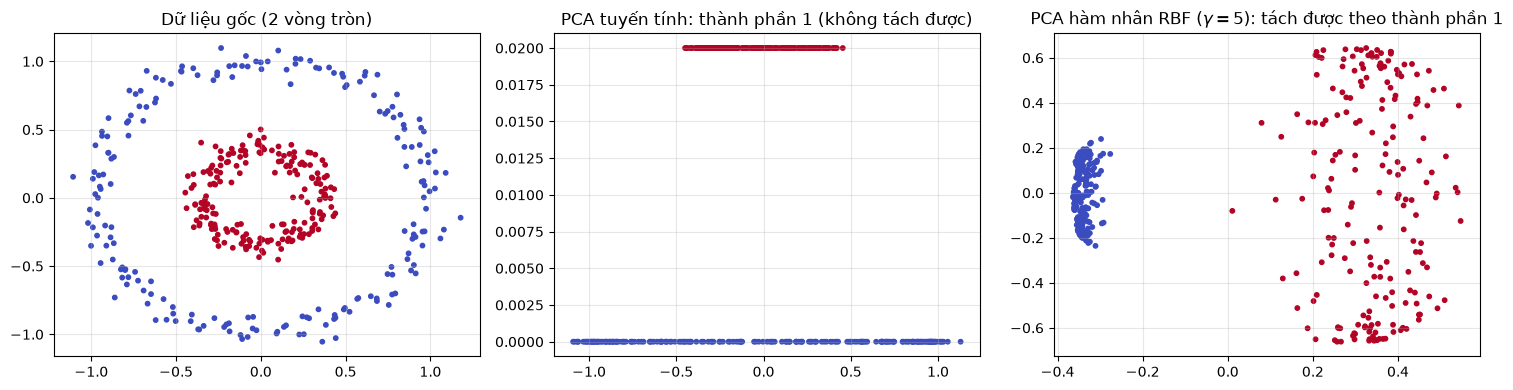

Độ chính xác tách 2 lớp chỉ bằng thành phần 1:
  PCA tuyến tính: 0.497
  PCA hàm nhân RBF, gamma =  1: 0.497
  PCA hàm nhân RBF, gamma =  2: 0.510
  PCA hàm nhân RBF, gamma =  5: 1.000
  PCA hàm nhân RBF, gamma = 10: 0.688
  PCA hàm nhân RBF, gamma = 15: 0.743


In [10]:
# (a) Nhân tuyến tính -> phải trùng PCA
kp_lin = KernelPCA_(3, kernel=linear_kernel).fit(Xw)
T_pca = (Xw - Xw.mean(0)) @ pca_svd(Xw, 3)[1]
print("Nhân tuyến tính: max |T_KPCA - T_PCA| (sau chuẩn hóa dấu) =",
      np.abs(fix_sign(kp_lin.train_scores_) - fix_sign(T_pca)).max())
print("Phương sai ell_j/(n-1):", kp_lin.ell_ / (len(Xw) - 1), "| PCA:", pca_svd(Xw, 3)[2][:3])

# (b) Nhân RBF: đối chiếu sklearn và minh họa trên dữ liệu hai vòng tròn
Xc_, yc_ = make_circles(n_samples=400, factor=0.35, noise=0.06, random_state=SEED)
gamma = 5.0
kp = KernelPCA_(2, gamma=gamma).fit(Xc_)
skk = KernelPCA(n_components=2, kernel="rbf", gamma=gamma).fit(Xc_)
print("RBF: max |T_tự cài - T_sklearn| (sau chuẩn hóa dấu) =",
      np.abs(fix_sign(kp.train_scores_) - fix_sign(skk.transform(Xc_))).max())
X_new = np.random.default_rng(SEED).uniform(-1, 1, (5, 2))
# Điểm mới: dấu của từng thành phần lấy theo tập huấn luyện nên so sánh trị tuyệt đối
print("RBF, chiếu điểm mới: max ||T_tự cài| - |T_sklearn|| =",
      np.abs(np.abs(kp.transform(X_new)) - np.abs(skk.transform(X_new))).max())

T_lin = (Xc_ - Xc_.mean(0)) @ pca_svd(Xc_, 2)[1]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(*Xc_.T, c=yc_, cmap="coolwarm", s=10); ax[0].set_title("Dữ liệu gốc (2 vòng tròn)")
ax[1].scatter(T_lin[:, 0], np.zeros_like(T_lin[:, 0]) + 0.02 * yc_, c=yc_, cmap="coolwarm", s=10)
ax[1].set_title("PCA tuyến tính: thành phần 1 (không tách được)")
ax[2].scatter(kp.train_scores_[:, 0], kp.train_scores_[:, 1], c=yc_, cmap="coolwarm", s=10)
ax[2].set_title(r"PCA hàm nhân RBF ($\gamma=5$): tách được theo thành phần 1")
plt.tight_layout(); plt.show()

# Độ tách lớp chỉ dùng thành phần 1 (ngưỡng tốt nhất bằng hồi quy logistic 1 chiều) theo gamma
from sklearn.linear_model import LogisticRegression
acc1 = lambda T: LogisticRegression().fit(T[:, :1], yc_).score(T[:, :1], yc_)
print("Độ chính xác tách 2 lớp chỉ bằng thành phần 1:")
print(f"  PCA tuyến tính: {acc1(T_lin):.3f}")
for g_ in [1, 2, 5, 10, 15]:
    print(f"  PCA hàm nhân RBF, gamma = {g_:>2}: {acc1(KernelPCA_(2, gamma=g_).fit(Xc_).train_scores_):.3f}")

### A.3.2 Bộ tự mã hóa tuyến tính huấn luyện bằng hạ gradient
Bộ mã hóa $E\in\mathbb{R}^{k\times d}$, bộ giải mã $D\in\mathbb{R}^{d\times k}$, mã $Z=X_cE^\top$, tái tạo $\hat X=ZD^\top=X_cE^\top D^\top$. Hàm mất mát
$$\mathcal L(E,D)=\frac1n\|X_c-X_cE^\top D^\top\|_F^2 .$$
Đặt $R=\hat X-X_c$. **Gradient** (tự dẫn xuất, không dùng tự động vi phân):
$$\nabla_D\mathcal L=\frac2n R^\top Z,\qquad \nabla_E\mathcal L=\frac2n D^\top R^\top X_c .$$
Theo **B.3**, cực tiểu toàn cục là $\mathcal L^\star=\frac1n\sum_{i>k}\sigma_i^2$, đạt khi ánh xạ tái tạo $DE$ là **phép chiếu trực giao** $V_kV_k^\top$ lên không gian con chính. Lưu ý $D$, $E$ riêng lẻ **không** nhất thiết trực chuẩn (có thể thay bằng $DG$, $G^{-1}E$ với $G$ khả nghịch bất kỳ) — chỉ không gian con $\mathrm{span}(D)$ và tích $DE$ là xác định.

In [11]:
# [CORE]
class LinearAutoencoder:
    # Tự mã hóa tuyến tính d -> k -> d, huấn luyện bằng hạ gradient toàn lô, gradient tự dẫn xuất
    def __init__(self, k, lr=0.05, n_iter=3000, seed=0):
        self.k, self.lr, self.n_iter, self.seed = k, lr, n_iter, seed

    def loss_and_grads(self, Xc, E, D):
        n = Xc.shape[0]
        Z = Xc @ E.T                       # n x k
        R = Z @ D.T - Xc                   # phần dư n x d
        loss = (R**2).sum() / n
        gD = 2.0 / n * R.T @ Z             # d x k
        gE = 2.0 / n * D.T @ R.T @ Xc      # k x d
        return loss, gE, gD

    def fit(self, X, track=None):
        rng = np.random.default_rng(self.seed)
        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        d = X.shape[1]
        E = 0.1 * rng.standard_normal((self.k, d))
        D = 0.1 * rng.standard_normal((d, self.k))
        self.history_ = []
        for it in range(self.n_iter):
            loss, gE, gD = self.loss_and_grads(Xc, E, D)
            E -= self.lr * gE
            D -= self.lr * gD
            if track is not None and (it % 20 == 0 or it == self.n_iter - 1):
                self.history_.append((it, loss, max_principal_angle_deg(D, track)))
        self.E_, self.D_ = E, D
        return self

    def reconstruct(self, X):
        return (X - self.mean_) @ self.E_.T @ self.D_.T + self.mean_

In [12]:
# Kiểm tra gradient bằng sai phân hữu hạn (đảm bảo công thức đạo hàm đúng)
rng = np.random.default_rng(SEED)
ae = LinearAutoencoder(3)
Xc_w = Xw - Xw.mean(0)
E0, D0 = rng.standard_normal((3, 13)), rng.standard_normal((13, 3))
_, gE, gD = ae.loss_and_grads(Xc_w, E0, D0)
h = 1e-6; num_E = np.zeros_like(E0); num_D = np.zeros_like(D0)
for idx in np.ndindex(E0.shape):
    Ep, Em = E0.copy(), E0.copy(); Ep[idx] += h; Em[idx] -= h
    num_E[idx] = (ae.loss_and_grads(Xc_w, Ep, D0)[0] - ae.loss_and_grads(Xc_w, Em, D0)[0]) / (2 * h)
for idx in np.ndindex(D0.shape):
    Dp, Dm = D0.copy(), D0.copy(); Dp[idx] += h; Dm[idx] -= h
    num_D[idx] = (ae.loss_and_grads(Xc_w, E0, Dp)[0] - ae.loss_and_grads(Xc_w, E0, Dm)[0]) / (2 * h)
print("Sai số tương đối gradient theo E:", np.linalg.norm(gE - num_E) / np.linalg.norm(num_E))
print("Sai số tương đối gradient theo D:", np.linalg.norm(gD - num_D) / np.linalg.norm(num_D))

Sai số tương đối gradient theo E: 6.254350324781728e-10
Sai số tương đối gradient theo D: 6.172432997124951e-10


Mất mát cuối / L* - 1          : 0 ± 0
Góc chính lớn nhất span(D), V_k : 7.29e-14 ± 4.48e-15 độ
max |DE - V_k V_k^T|           : 1.78e-15 ± 2.65e-16   -> DE là phép chiếu trực giao lên không gian con chính
max |D^T D - I|                : 0.0377 ± 0.0135   -> D không nhất thiết trực chuẩn


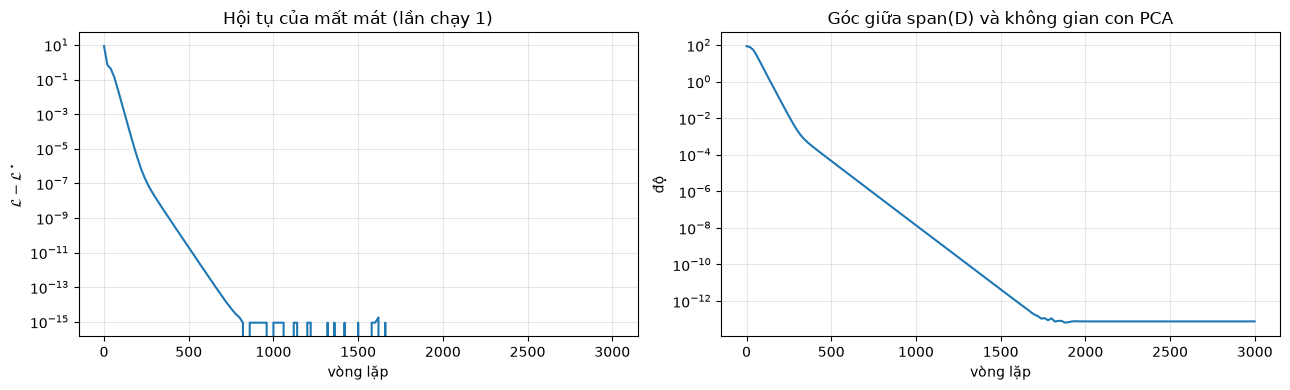

In [13]:
k = 3
n = len(Xw)
_, Vk, lam_w = pca_svd(Xw, k)
L_star = (n - 1) / n * lam_w[k:].sum()          # (1/n) sum_{i>k} sigma_i^2
lr = 0.4 / ((n - 1) / n * lam_w[0])              # bước học theo độ cong lớn nhất ~ lambda_1

finals, angles, proj_err, orth_err = [], [], [], []
for r in range(N_RUNS):
    ae = LinearAutoencoder(k, lr=lr, n_iter=3000, seed=SEED + r).fit(Xw, track=Vk)
    it, loss, a = ae.history_[-1]
    finals.append(loss / L_star - 1); angles.append(a)
    proj_err.append(np.abs(ae.D_ @ ae.E_ - Vk @ Vk.T).max())           # DE so với phép chiếu V_k V_k^T
    orth_err.append(np.abs(ae.D_.T @ ae.D_ - np.eye(k)).max())         # D có trực chuẩn không?
    if r == 0:
        hist = np.array(ae.history_)

print(f"Mất mát cuối / L* - 1          : {mean_std(finals)}")
print(f"Góc chính lớn nhất span(D), V_k : {mean_std(angles)} độ")
print(f"max |DE - V_k V_k^T|           : {mean_std(proj_err)}   -> DE là phép chiếu trực giao lên không gian con chính")
print(f"max |D^T D - I|                : {mean_std(orth_err)}   -> D không nhất thiết trực chuẩn")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].semilogy(hist[:, 0], hist[:, 1] - L_star); ax[0].set(xlabel="vòng lặp", ylabel=r"$\mathcal{L}-\mathcal{L}^\star$", title="Hội tụ của mất mát (lần chạy 1)")
ax[1].semilogy(hist[:, 0], hist[:, 2]); ax[1].set(xlabel="vòng lặp", ylabel="độ", title="Góc giữa span(D) và không gian con PCA")
plt.tight_layout(); plt.show()

**Kết luận A.3.** PCA hàm nhân phụ thuộc mạnh vào tham số $\gamma$ (cần chọn trên dữ liệu kiểm định): $\gamma=5$ tách hoàn toàn hai vòng tròn bằng một thành phần, $\gamma$ quá nhỏ thì gần tuyến tính, quá lớn thì mỗi điểm chỉ "thấy" lân cận rất hẹp. Hạ gradient đưa mất mát về đúng giá trị tối ưu Eckart–Young và không gian con của bộ giải mã hội tụ về không gian con PCA (góc → 0); tích $DE$ trùng phép chiếu $V_kV_k^\top$ dù $D$ không trực chuẩn — đúng như mệnh đề B.3. PCA hàm nhân với nhân tuyến tính trùng PCA; với nhân RBF nó bắt được cấu trúc phi tuyến mà PCA bỏ lỡ.

---
## A.4 Thống kê giám sát $T^2$ Hotelling và SPE ($Q$)

Mô hình PCA học từ dữ liệu **trạng thái bình thường** (đã chuẩn hóa) chia không gian thành hai phần: không gian con chính (k chiều, chứa biến thiên "hợp lệ") và không gian dư. Với mẫu mới $x$ (đã chuẩn hóa bằng trung bình/độ lệch chuẩn của dữ liệu huấn luyện), $t=P^\top x$ với $P=V_k$:

| Thống kê | Công thức | Phát hiện |
|---|---|---|
| $T^2$ Hotelling | $T^2=\sum_{i=1}^k t_i^2/\lambda_i$ | Biến thiên **bất thường về độ lớn** nhưng vẫn theo cấu trúc tương quan cũ |
| SPE / $Q$ | $Q=\|x-PP^\top x\|^2$ | **Phá vỡ cấu trúc tương quan** (điểm rời khỏi không gian con chính) |

**Giới hạn kiểm soát lý thuyết** ở mức ý nghĩa $\alpha$ (tỉ lệ báo động giả mong muốn):
- $T^2$, hiệp phương sai biết trước (B.6): $T^2_\alpha=\chi^2_{k,1-\alpha}$.
- $T^2$, hiệp phương sai ước lượng từ $n$ mẫu, cho **quan sát mới**: $T^2_\alpha=\dfrac{k(n-1)(n+1)}{n(n-k)}F_{k,\,n-k,\,1-\alpha}$.
- SPE, Jackson & Mudholkar (1979): với $\theta_j=\sum_{i>k}\lambda_i^j$, $h_0=1-\dfrac{2\theta_1\theta_3}{3\theta_2^2}$, $c_\alpha=\operatorname{sign}(h_0)\,\Phi^{-1}(1-\alpha)$ (lấy **cùng dấu với $h_0$**; $h_0<0$ xảy ra khi các trị riêng phần dư rất chênh lệch, khi đó phép biến đổi $(Q/\theta_1)^{h_0}$ là hàm giảm):
$$Q_\alpha=\theta_1\left[\frac{c_\alpha\sqrt{2\theta_2h_0^2}}{\theta_1}+1+\frac{\theta_2h_0(h_0-1)}{\theta_1^2}\right]^{1/h_0}.$$
- SPE, xấp xỉ Box (1954): $Q\approx g\chi^2_h$ với $g=\theta_2/\theta_1$, $h=\theta_1^2/\theta_2$.

**Giới hạn thực nghiệm:** phân vị $1-\alpha$ của $T^2$, SPE trên một tập **kiểm định gồm dữ liệu bình thường** không dùng để huấn luyện. Cần thiết khi dữ liệu không chuẩn (đặc trưng rung thường lệch phải).

In [14]:
# [CORE]
class PCAMonitor:
    # Giám sát quá trình bằng PCA: T^2 Hotelling + SPE (Q) với giới hạn lý thuyết và thực nghiệm
    def __init__(self, k=None, var_ratio=0.90, alpha=0.01):
        self.k, self.var_ratio, self.alpha = k, var_ratio, alpha

    def fit(self, X):
        n, d = X.shape
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0, ddof=1)
        self.std_[self.std_ == 0] = 1.0
        Z = (X - self.mean_) / self.std_                      # chuẩn hóa bằng thống kê của dữ liệu bình thường
        _, S, Vt = np.linalg.svd(Z, full_matrices=False)
        lam = S**2 / (n - 1)
        if self.k is None:                                    # chọn k theo tỉ lệ phương sai tích lũy
            self.k = int(np.searchsorted(np.cumsum(lam) / lam.sum(), self.var_ratio) + 1)
        k, a = self.k, self.alpha
        self.P_, self.lam_, self.n_ = Vt[:k].T, lam, n
        # Giới hạn T^2
        self.T2_lim_chi2_ = stats.chi2.ppf(1 - a, k)
        self.T2_lim_F_ = k * (n - 1) * (n + 1) / (n * (n - k)) * stats.f.ppf(1 - a, k, n - k)
        # Giới hạn SPE
        res = lam[k:]
        th1, th2, th3 = res.sum(), (res**2).sum(), (res**3).sum()
        h0 = 1 - 2 * th1 * th3 / (3 * th2**2)
        ca = np.sign(h0) * stats.norm.ppf(1 - a)              # c_alpha lấy cùng dấu với h0 (Jackson-Mudholkar 1979)
        self.SPE_lim_JM_ = th1 * (ca * np.sqrt(2 * th2 * h0**2) / th1 + 1 + th2 * h0 * (h0 - 1) / th1**2) ** (1 / h0)
        g, h = th2 / th1, th1**2 / th2
        self.SPE_lim_box_ = g * stats.chi2.ppf(1 - a, h)
        return self

    def scores(self, X):
        Z = (X - self.mean_) / self.std_
        T = Z @ self.P_                                       # tọa độ trên các thành phần chính
        T2 = (T**2 / self.lam_[:self.k]).sum(axis=1)
        E = Z - T @ self.P_.T                                 # phần dư ngoài không gian con chính
        SPE = (E**2).sum(axis=1)
        return T2, SPE

    def fit_empirical_limits(self, X_val):
        T2, SPE = self.scores(X_val)
        self.T2_lim_emp_ = np.quantile(T2, 1 - self.alpha)
        self.SPE_lim_emp_ = np.quantile(SPE, 1 - self.alpha)
        return self

    def limits(self, kind="theory"):
        if kind == "theory":
            return self.T2_lim_F_, self.SPE_lim_JM_
        return self.T2_lim_emp_, self.SPE_lim_emp_

    def predict(self, X, kind="theory", rule="either"):
        # Trả về mảng bool: True = báo động. rule: "T2", "SPE" hoặc "either"
        T2, SPE = self.scores(X)
        t_lim, q_lim = self.limits(kind)
        a_T, a_Q = T2 > t_lim, SPE > q_lim
        return {"T2": a_T, "SPE": a_Q, "either": a_T | a_Q}[rule]

### A.4.1 Kiểm chứng trên quá trình mô phỏng
Quá trình $d=20$ cảm biến sinh từ $3$ nhân tố ẩn: $x = Lf + e$, $f\sim\mathcal N(0,I_3)$, $e\sim\mathcal N(0,0.3^2I)$. Huấn luyện trên 1000 mẫu bình thường, ngưỡng thực nghiệm trên 1000 mẫu bình thường khác, kiểm tra trên:
- **bình thường** (2000 mẫu) → tỉ lệ báo động giả phải xấp xỉ $\alpha=1\%$;
- **lỗi 1 – dịch chuyển trong mô hình:** nhân tố 1 tăng thêm $5$ (biến thiên lớn nhưng *đúng cấu trúc tương quan*) → kỳ vọng $T^2$ phát hiện, SPE thì không;
- **lỗi 2 – lệch một cảm biến:** cảm biến số 5 lệch $+3$ (*phá vỡ tương quan*) → kỳ vọng SPE phát hiện.

In [15]:
def simulate_process(n, L, rng, fault=None):
    f = rng.standard_normal((n, L.shape[1]))
    if fault == "shift":
        f[:, 0] += 5.0
    X = f @ L.T + 0.3 * rng.standard_normal((n, L.shape[0]))
    if fault == "sensor":
        X[:, 4] += 3.0
    return X

rows = {key: [] for key in ["FA_T2_chi2", "FA_T2_F", "FA_SPE_JM", "FA_SPE_box", "FA_T2_emp", "FA_SPE_emp",
                            "shift_T2", "shift_SPE", "sensor_T2", "sensor_SPE"]}
for r in range(N_RUNS):
    rng = np.random.default_rng(SEED + r)
    L = rng.standard_normal((20, 3))
    mon = PCAMonitor(k=3, alpha=0.01).fit(simulate_process(1000, L, rng))
    mon.fit_empirical_limits(simulate_process(1000, L, rng))
    T2, SPE = mon.scores(simulate_process(2000, L, rng))
    rows["FA_T2_chi2"].append(np.mean(T2 > mon.T2_lim_chi2_)); rows["FA_T2_F"].append(np.mean(T2 > mon.T2_lim_F_))
    rows["FA_SPE_JM"].append(np.mean(SPE > mon.SPE_lim_JM_)); rows["FA_SPE_box"].append(np.mean(SPE > mon.SPE_lim_box_))
    rows["FA_T2_emp"].append(np.mean(T2 > mon.T2_lim_emp_)); rows["FA_SPE_emp"].append(np.mean(SPE > mon.SPE_lim_emp_))
    for fault in ["shift", "sensor"]:
        T2f, SPEf = mon.scores(simulate_process(500, L, rng, fault))
        rows[f"{fault}_T2"].append(np.mean(T2f > mon.T2_lim_F_)); rows[f"{fault}_SPE"].append(np.mean(SPEf > mon.SPE_lim_JM_))

print("TỈ LỆ BÁO ĐỘNG GIẢ trên dữ liệu bình thường (mục tiêu alpha = 0.01):")
for key, name in [("FA_T2_chi2", "T2, chi2_k"), ("FA_T2_F", "T2, phân phối F"), ("FA_T2_emp", "T2, thực nghiệm"),
                  ("FA_SPE_JM", "SPE, Jackson-Mudholkar"), ("FA_SPE_box", "SPE, Box g*chi2_h"), ("FA_SPE_emp", "SPE, thực nghiệm")]:
    print(f"  {name:<24}: {mean_std(rows[key], '.4f')}")
print("\nTỈ LỆ PHÁT HIỆN (giới hạn lý thuyết):")
print(f"  Lỗi 1 (dịch chuyển trong mô hình): T2 = {mean_std(rows['shift_T2'], '.3f')} | SPE = {mean_std(rows['shift_SPE'], '.3f')}")
print(f"  Lỗi 2 (lệch một cảm biến)        : T2 = {mean_std(rows['sensor_T2'], '.3f')} | SPE = {mean_std(rows['sensor_SPE'], '.3f')}")

TỈ LỆ BÁO ĐỘNG GIẢ trên dữ liệu bình thường (mục tiêu alpha = 0.01):
  T2, chi2_k              : 0.0125 ± 0.0025
  T2, phân phối F         : 0.0119 ± 0.0023
  T2, thực nghiệm         : 0.0145 ± 0.0057
  SPE, Jackson-Mudholkar  : 0.0075 ± 0.0015
  SPE, Box g*chi2_h       : 0.0162 ± 0.0035
  SPE, thực nghiệm        : 0.0115 ± 0.0014

TỈ LỆ PHÁT HIỆN (giới hạn lý thuyết):
  Lỗi 1 (dịch chuyển trong mô hình): T2 = 0.969 ± 0.011 | SPE = 0.008 ± 0.003
  Lỗi 2 (lệch một cảm biến)        : T2 = 0.014 ± 0.006 | SPE = 0.958 ± 0.057


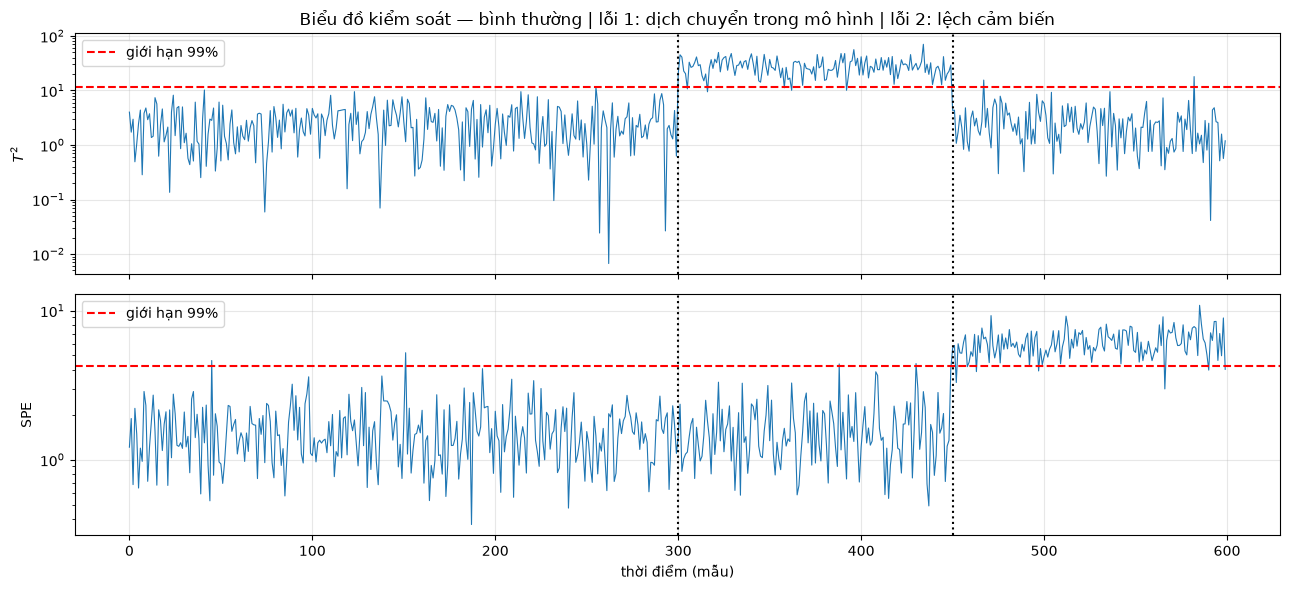

In [16]:
# Biểu đồ kiểm soát: 300 mẫu bình thường, rồi 150 mẫu lỗi 1, rồi 150 mẫu lỗi 2
rng = np.random.default_rng(SEED)
L = rng.standard_normal((20, 3))
mon = PCAMonitor(k=3, alpha=0.01).fit(simulate_process(1000, L, rng))
X_seq = np.vstack([simulate_process(300, L, rng), simulate_process(150, L, rng, "shift"), simulate_process(150, L, rng, "sensor")])
T2, SPE = mon.scores(X_seq)
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for a_, val, lim, name in [(ax[0], T2, mon.T2_lim_F_, r"$T^2$"), (ax[1], SPE, mon.SPE_lim_JM_, "SPE")]:
    a_.semilogy(val, lw=0.8); a_.axhline(lim, c="r", ls="--", label="giới hạn 99%")
    for x0 in [300, 450]: a_.axvline(x0, c="k", ls=":")
    a_.set_ylabel(name); a_.legend(loc="upper left")
ax[0].set_title("Biểu đồ kiểm soát — bình thường | lỗi 1: dịch chuyển trong mô hình | lỗi 2: lệch cảm biến")
ax[1].set_xlabel("thời điểm (mẫu)")
plt.tight_layout(); plt.show()

**Kết luận A.4.** Các giới hạn lý thuyết cho tỉ lệ báo động giả sát $\alpha=1\%$ khi dữ liệu chuẩn (giới hạn $F$ chính xác hơn $\chi^2$ vì tính đến sai số ước lượng hiệp phương sai). Hai thống kê **bổ sung cho nhau**: $T^2$ bắt lỗi trong không gian con chính, SPE bắt lỗi phá vỡ tương quan. Ở Phần D cần dùng **cả hai** (quy tắc "either"), và ưu tiên giới hạn thực nghiệm nếu đặc trưng rung không tuân theo phân phối chuẩn.

---
## Kiểm tra đồng bộ với `src/pca_core.py`
Notebook 2, 3 và Phần D dùng các cài đặt từ file `pca_core.py`. Ô dưới so sánh kết quả của file đó với các cài đặt trong notebook này trên cùng dữ liệu, cùng hạt giống.

In [17]:
import os, sys
for p in ["../src", "src", "."]:
    if os.path.exists(os.path.join(p, "pca_core.py")):
        sys.path.insert(0, os.path.abspath(p)); break
import pca_core as pc

rng = np.random.default_rng(SEED)
A_t = make_spectrum_matrix(300, 80, 1 / np.sqrt(np.arange(1, 81)), rng)
X_t = rng.standard_normal((500, 8)) @ rng.standard_normal((8, 8))
checks = {
    "pca_eig":          np.allclose(pc.pca_eig(Xw, 4)[2], pca_eig(Xw, 4)[2]),
    "pca_svd":          np.allclose(fix_sign(pc.pca_svd(Xw, 4)[1]), fix_sign(pca_svd(Xw, 4)[1])),
    "randomized_svd":   np.allclose(pc.randomized_svd(A_t, 5, rng=1)[1], randomized_svd(A_t, 5, rng=1)[1]),
    "StreamingPCA":     np.allclose(pc.StreamingPCA(3).partial_fit(X_t[:250]).partial_fit(X_t[250:]).explained_variance_,
                                    StreamingPCA(3).partial_fit(X_t[:250]).partial_fit(X_t[250:]).explained_variance_),
    "KernelPCA_":       np.allclose(pc.KernelPCA_(2, gamma=5.0).fit(Xc_).train_scores_, KernelPCA_(2, gamma=5.0).fit(Xc_).train_scores_),
    "LinearAutoencoder": np.allclose(pc.LinearAutoencoder(3, lr=0.01, n_iter=200, seed=1).fit(Xw).D_,
                                     LinearAutoencoder(3, lr=0.01, n_iter=200, seed=1).fit(Xw).D_),
    "PCAMonitor":       np.allclose(pc.PCAMonitor(k=3).fit(X_t).scores(X_t)[1], PCAMonitor(k=3).fit(X_t).scores(X_t)[1]),
}
for name, ok in checks.items():
    print(f"{name:<18}: {'khớp' if ok else 'KHÔNG KHỚP -> cần đồng bộ lại pca_core.py'}")

pca_eig           : khớp
pca_svd           : khớp
randomized_svd    : khớp
StreamingPCA      : khớp
KernelPCA_        : khớp
LinearAutoencoder : khớp
PCAMonitor        : khớp
